In [48]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join('..')))

In [49]:
## Importing files
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sea
from src.data import load_csv

In [50]:
from src.models import MultipleLinearRegression

In [51]:
df = load_csv("../data/hour.csv")

In [52]:
df

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,119
17375,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,89
17376,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,90
17377,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,61


In [53]:
class SGDMultipleLinearRegression():

    def __init__(self):
        self.beta_hat = None
        self.intercept_ = None
        self.coef_ = None
        self.lr_ = None
        self.lr_limit_ = None
        self.loss_history_ = None
        self.n_iter_ = None

    def _add_intercept(self, X):
        X = np.asarray(X, float)

        return np.c_[np.ones(X.shape[0]), X]


    def fit_sgd(self, X, y, batch_size=None, lr=None, epochs=1000,):
        X = np.asarray(X, float)
        y = np.asarray(y, float).ravel()

        X = self._add_intercept(X)    

        self.beta_hat = np.zeros(X.shape[1])

        tolerance = 1e-08
        self.loss_history_ = []
        self.n_iter_ = epochs
        if batch_size is None:
            batch_size = X.shape[0]

        for epoch in range(epochs):
            indices = np.arange(len(X))
            np.random.shuffle(indices)
            for start_index in range(0, len(X), batch_size):

                batch_indices = indices[start_index:start_index + batch_size]
        
                X_batch = X[batch_indices]
                y_batch = y[batch_indices]
                B = X_batch.shape[0]
                X_bTX_b = X_batch.T @ X_batch
                H_b = (2/B) * X_bTX_b
                
                eigen_values = np.linalg.eigvalsh(H_b)
                max_ev = np.max(eigen_values)
                
                self.lr_ = lr if lr is not None else 1/max_ev
                self.lr_limit_ = 2 / max_ev
                if self.lr_ > self.lr_limit_:
                    print("Warning: lr_ is at or above the stability limit, expect divergence!")

            ## real cooking: 
                y_pred = X_batch @ self.beta_hat
                e = y_batch - y_pred
                gradient = -(2/B) * X_batch.T @ (y_batch - y_pred)
                self.beta_hat = self.beta_hat - self.lr_ * gradient


            print(len(e))
            loss = np.mean((e)**2)
            self.n_iter_ = epoch + 1
            self.loss_history_.append(loss)

            if not np.isfinite(loss):
                print("Diverged at: ", epoch)
                break

            if epoch > 0 and abs(self.loss_history_[-2] - self.loss_history_[-1]) < tolerance:
                print("Converged at: ", epoch)
                break

        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def predict(self, X):
        if self.beta_hat is None:
            print(".fit() not called yet, please fit the data")
        X = np.asarray(X, float)
        X = self._add_intercept(X)

        return X @  self.beta_hat

try to do it in vectorised way and then benchmark both the loops okay

In [54]:
features = ['atemp', 'hum', 'windspeed']
target = ['cnt']

X = df[features]
y = df[target]




In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, shuffle=False, test_size=0.2)

In [56]:
model = SGDMultipleLinearRegression()
model.fit_sgd(X_train, y_train, batch_size=1, epochs=5)

1
1
1
1
1


In [57]:
model.loss_history_[-5:]

[np.float64(12158.49428935677),
 np.float64(670.9424210544815),
 np.float64(13143.14861357163),
 np.float64(0.23380304396703497),
 np.float64(22490.820692932677)]

What will len print fo B=32 and B=1 i think 32 and 1 only !! letsee
for b=1, it will be len(e) will be 1 for 13903 time
It was 15 for B=32 

In [58]:
print("Beta Parameter vector: ", model.beta_hat)
print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)
print(abs(model.loss_history_[-2] - model.loss_history_[-1]))


Beta Parameter vector:  [ 117.42447279  299.29902158 -103.99218647   85.90173914]
Intercept:  117.42447279403414
Coefficients:  [ 299.29902158 -103.99218647   85.90173914]
22490.58688988871


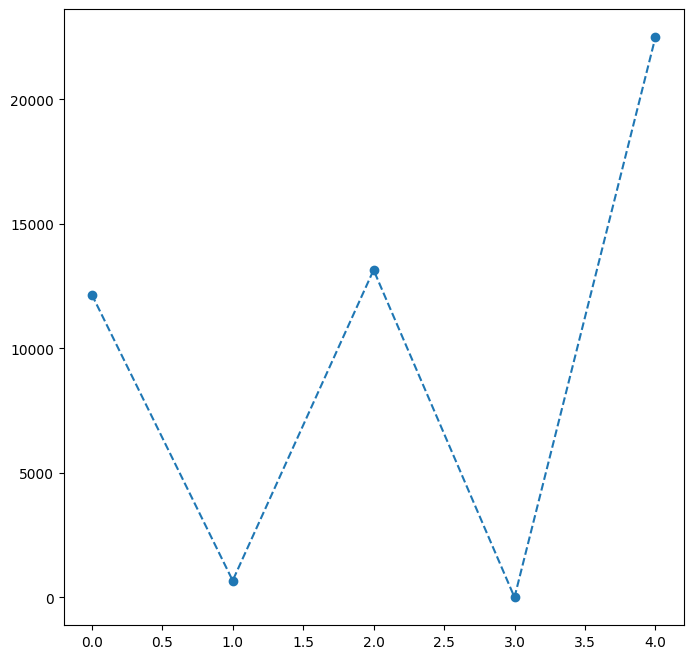

In [59]:
plt.figure(figsize=(8,8))
plt.plot(model.loss_history_, marker='o', linestyle='--')

i think the number of epochs fell short !! Let me increase the number of epochs to 2000

In [60]:
model = SGDMultipleLinearRegression()

model.fit_sgd(X_train, y_train,epochs=2000)

print("Beta Parameter vector: ", model.beta_hat)
print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)
print(abs(model.loss_history_[-2] - model.loss_history_[-1]))

13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
1390

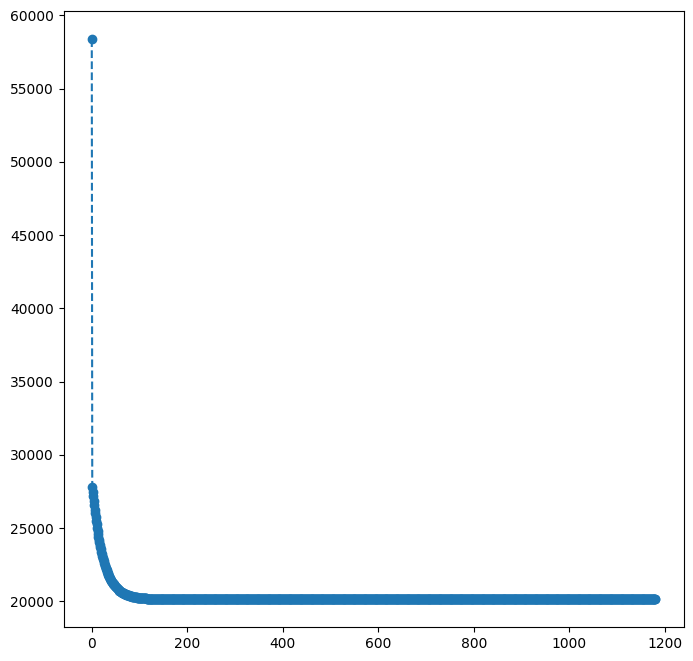

In [61]:
plt.figure(figsize=(8,8))
plt.plot(model.loss_history_, marker='o', linestyle='--')
plt.show()

I was god damn right !!!

I will now use scaled X_train and y_train

In [62]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_train)
y_scaled = scaler.fit_transform(y_train)

print("Epoch= 1000 by default")
model = SGDMultipleLinearRegression()
model.fit_sgd(X_scaled, y_train)
print("Beta Parameter vector: ", model.beta_hat)
print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)
print(abs(model.loss_history_[-2] - model.loss_history_[-1]))


print(" \nEpoch= 2000")
model = SGDMultipleLinearRegression()
model.fit_sgd(X_scaled, y_train)
print("Beta Parameter vector: ", model.beta_hat)
print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)
print(abs(model.loss_history_[-2] - model.loss_history_[-1]))

Epoch= 1000 by default
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
Converged at:  16
Beta Parameter vector:  [174.63914263  69.07493593 -49.2796837    6.83422239]
Intercept:  174.63914262939085
Coefficients:  [ 69.07493593 -49.2796837    6.83422239]
8.32369551062584e-09
 
Epoch= 2000
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
13903
Converged at:  16
Beta Parameter vector:  [174.63914263  69.07493593 -49.2796837    6.83422239]
Intercept:  174.63914262939088
Coefficients:  [ 69.07493593 -49.2796837    6.83422239]
8.32369551062584e-09


In [63]:
model.loss_history_

import matplotlib.pyplot as plt
import seaborn as sea

They are saying that my code will lead to some bugs if the Batch Size B gets small: Let me try it out, i dont think any of that will happen, as why will batch size 
1. I think i must declare lr_ before the loop and not in the loop 
2. fix a seed i think !! 
3. the loss claude was talking about.

In [64]:
class SGDMultipleLinearRegression():

    def __init__(self):
        self.beta_hat = None
        self.intercept_ = None
        self.coef_ = None
        self.lr_ = None
        self.lr_limit_ = None
        self.loss_history_ = None
        self.n_iter_ = None

    def _add_intercept(self, X):
        X = np.asarray(X, float)

        return np.c_[np.ones(X.shape[0]), X]


    def fit_sgd(self, X, y, batch_size=None, lr=None, epochs=1000,tolerance=1e-08, seed=42, shuffle=False, decay_rate=0.0,
                decay_type=None, patience=5):

        """

        batch_size: an int value for creating mini batches out of the whole data
        lr: learning rate if None use 1/max_ev of X (complete)
        epochs: number of iterations we iterate updating our parameters
        tolerance: checks whether the step size is less than this, if yes we have converged our beta hat at the correct place, 
        checks if step btw two losses is less than tolerance if yes, we declare it as converged !!

        in reality: threshold for the absolute difference between consecutive loss values;
        training stops early if change in loss fallss below this value !! 

        seed: for our rng to start at this seed number only
        shuffle: if you wanna shuffle the data or not 
        decay_type = "time", "exponential" and "plateau" or None
        decay_rate : float value controlling the decay speed/factor
        patience: number of epochs to wait without improvement before reducing lr for plateuau decay !!
        """
        X = np.asarray(X, float)
        y = np.asarray(y, float).ravel()

        X = self._add_intercept(X)   # Build the design matrix with intercept.  

        self.beta_hat = np.zeros(X.shape[1]) #initialise intercept and slope to be ZERO: 0

        n = X.shape[0]#number of rows for hessian matrix
        XTX = X.T @ X # make the X matrix Squared..! 
        H = (2/n) * XTX # calculating Hessian Matrix using formula (2/n) * XTX
        #before loop using all of the dataset !! 

        eigen_values = np.linalg.eigvalsh(H) #evalue of whole dataset. 
        max_ev = np.max(eigen_values)   #max from whole dataset. 

        self.lr_ = lr if lr is not None else 1 / max_ev #take lr if given else initialise you own 
        self.lr_limit_ = 2 / max_ev
        initial_lr = self.lr_

        if self.lr_ >= self.lr_limit_:
            print("Warning! lr_ is at or above the stability limit, expect divergence.")

        tolerance = tolerance #tolerance meaning lr must not be less than 1e-08
        self.loss_history_ = []
        self.n_iter_ = epochs

        if batch_size is None: #if batch size isnot given, take the whole array of X
            batch_size = X.shape[0]
        rng = np.random.default_rng(seed) #seed to keep a fixed start okay !!

        ## decay rate:
        best_loss = np.inf
        epochs_without_improvement = 0


        for epoch in range(epochs):
            
            indices = np.arange(len(X))
            if shuffle:
                rng.shuffle(indices)

            y_pred = X @ self.beta_hat #fit the whole complete X with the current beta get the loss and chec is loss is finite or not ! 
            loss = np.mean((y - y_pred)**2) #recording full dataset loss each epoch, before updates. 

            if not np.isfinite(loss):
                print("Diverged at: ", epoch)
                break

            self.loss_history_.append(loss)

            for start_index in range(0, len(X), batch_size): #make batches, find gradient, update 

                batch_indices = indices[start_index:start_index + batch_size]
        
                X_batch = X[batch_indices]
                y_batch = y[batch_indices]
                B = X_batch.shape[0]

            ## real cooking: 
                y_pred = X_batch @ self.beta_hat
                gradient = -(2/B) * X_batch.T @ (y_batch - y_pred) #the gradient points uphill to the highest slope, so we negate it t point to the smallest/lowest slope okay !!
                self.beta_hat = self.beta_hat - self.lr_ * gradient

            self.n_iter_ = epoch + 1


#--------------------------------------------------------------------------------
            if decay_type == "time":
                self.lr_ = initial_lr / (1 + decay_rate * epoch)

            elif decay_type == "exponential":
                self.lr_ = initial_lr * np.exp(-decay_rate * epoch)

            elif decay_type == "plateau":

                if loss < best_loss - tolerance:
                    best_loss = loss 
                    epochs_without_improvement = 0

                else:
                    epochs_without_improvement += 1
                    if epochs_without_improvement >=patience:
                        self.lr_ = self.lr_ * decay_rate
                        epochs_without_improvement = 0

#------------------------------------------------------------------------------------

            if epoch > 0 and abs(self.loss_history_[-2] - self.loss_history_[-1]) < tolerance:
                print("Converged at: ", epoch)
                break

        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def predict(self, X):
        if self.beta_hat is None:
            raise ValueError(".fit() not called yet, please fit the data")
        X = np.asarray(X, float)
        X = self._add_intercept(X)

        return X @  self.beta_hat

Model Beta Hat: 
[ 131.79069977  391.12627289 -248.64365657   55.57594232]
Model's first loss == np.mean(y**2):  58370.9353376969
58370.9353376969


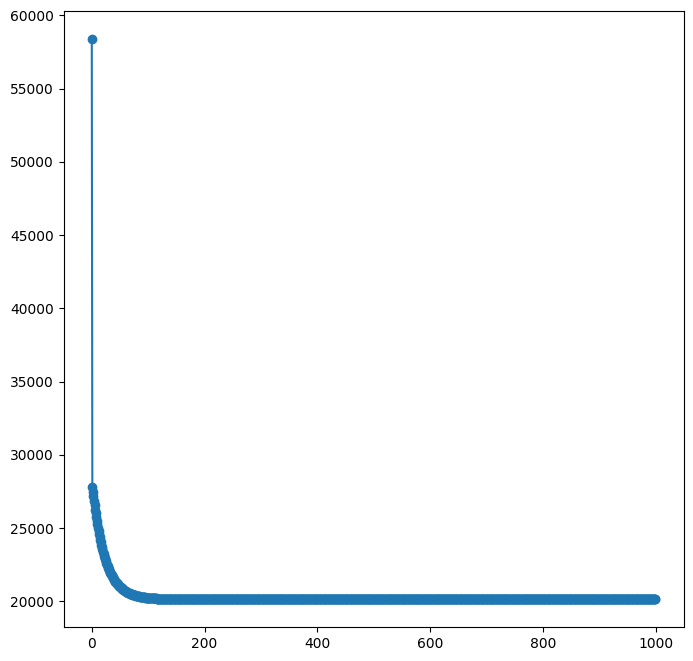

In [65]:
model = SGDMultipleLinearRegression()

model.fit_sgd(X_train, y_train)

print("Model Beta Hat: ")
print(model.beta_hat)

print("Model's first loss == np.mean(y**2): ",np.mean(y_train**2))
print(model.loss_history_[0])


plt.figure(figsize=(8,8))
plt.plot(model.loss_history_, marker='o')
plt.show()

### Our model has not converged our dear x_train and y_train so i think we need to increase the EPOCH !!

In [66]:
model= SGDMultipleLinearRegression()
model.fit_sgd(X_train, y_train,epochs=2000)

Converged at:  1180


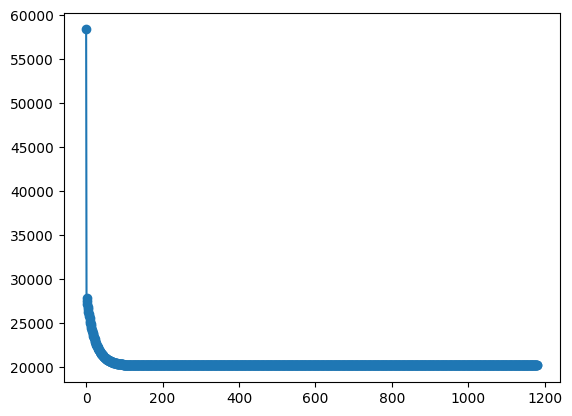

In [67]:
plt.plot(model.loss_history_, marker='o')

In [68]:
model = SGDMultipleLinearRegression()
model.fit_sgd(X_train, y_train, batch_size=1, epochs=2000)

Converged at:  21


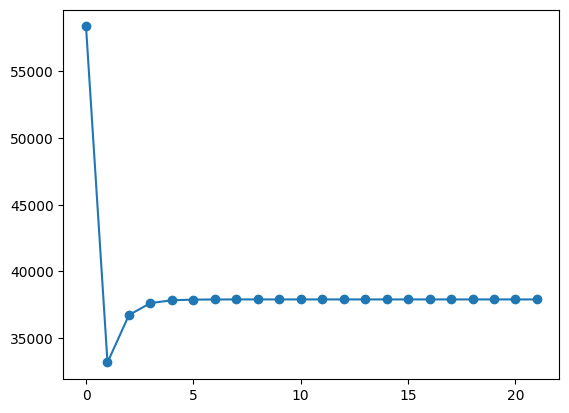

In [69]:
plt.plot(model.loss_history_, marker='o')

There might be two main reason our model is not converging, first being the data is not standardised and second being that the learning rate is constant, so i need to add a decaying rate something okay !! I dontknow how decaying works right now but let us standardise my dataset and then try with B = 64, 32, 1 and Epochs = 1000, 1500 and 2000

The good thing is that our loss is not fluctuating as it did when we tried to calculate on samples and not the entire dataset !

It converged and that too at 21, batch = 1, epochs = 2000 !!

## Standardising Dataset

In [70]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_sc = scaler.fit_transform(X_train)
y_sc = scaler.fit_transform(y_train)

Benchmarking: B = N, baseline losssed and baseline beta

In [71]:
model = SGDMultipleLinearRegression()

model.fit_sgd(X_sc, y_train, shuffle=True)

baseline_losses = model.loss_history_.copy()

baseline_beta = model.beta_hat.copy()

Converged at:  16


In [37]:
print(model.intercept_, model.coef_)

174.63914262939088 [ 69.07493593 -49.2796837    6.83422239]


In [38]:
print("Losses: ", baseline_losses)

print("\n \nBeta: ", baseline_beta)

Losses:  [np.float64(58370.9353376969), np.float64(21953.526054082256), np.float64(20229.20552012403), np.float64(20140.848643195775), np.float64(20135.859506596993), np.float64(20135.482494148342), np.float64(20135.435869629782), np.float64(20135.42751214574), np.float64(20135.425787201177), np.float64(20135.425417454353), np.float64(20135.425337475594), np.float64(20135.425320138984), np.float64(20135.425316379173), np.float64(20135.425315563672), np.float64(20135.425315386794), np.float64(20135.425315348428), np.float64(20135.425315340104)]

 
Beta:  [174.63914263  69.07493593 -49.2796837    6.83422239]


SEEEE i was correct, it converged at 16 only, let us try to batch it now !!

In [20]:
print("For Batch_Size = 64 and epochs= 1000 or 500")
model = SGDMultipleLinearRegression()

model.fit_sgd(X_sc, y_train, batch_size=64, epochs=1000)


print("For Batch_Size = 32 and epochs= 1000 or 500")

model = SGDMultipleLinearRegression()

model.fit_sgd(X_sc, y_train, batch_size=32, epochs=1000)


print("For Batch_Size = 1 and epochs=1500")

model = SGDMultipleLinearRegression()

model.fit_sgd(X_sc, y_train, batch_size=1, epochs=1500)

For Batch_Size = 64 and epochs= 1000 or 500
Converged at:  5
For Batch_Size = 32 and epochs= 1000 or 500
Diverged at:  54
For Batch_Size = 1 and epochs=1500
Diverged at:  1


C:\Users\Sarthak\AppData\Local\Temp\ipykernel_30820\2665707110.py:80: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - y_pred)**2) #recording full dataset loss each epoch, before updates.
c:\Users\Sarthak\anaconda3\Lib\site-packages\numpy\_core\_methods.py:134: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Sarthak\AppData\Local\Temp\ipykernel_30820\2665707110.py:98: RuntimeWarning: overflow encountered in matmul
  gradient = -(2/B) * X_batch.T @ (y_batch - y_pred) #the gradient points uphill to the highest slope, so we negate it t point to the smallest/lowest slope okay !!
C:\Users\Sarthak\AppData\Local\Temp\ipykernel_30820\2665707110.py:99: RuntimeWarning: invalid value encountered in subtract
  self.beta_hat = self.beta_hat - self.lr_ * gradient


Note: it did not converge for B = 64 and 32 when epoch was 1000, and it diverged at 1 for B = 1

In [21]:
print("For Batch_Size = 2000")
model = SGDMultipleLinearRegression()

model.fit_sgd(X_sc, y_train, batch_size=13903, epochs=2000)

For Batch_Size = 2000
Converged at:  16


tried for many batches, but not convergining, i dont know why but let us see

now dropping my converging condition from 1e-08 to 1e-04

Converged at:  3


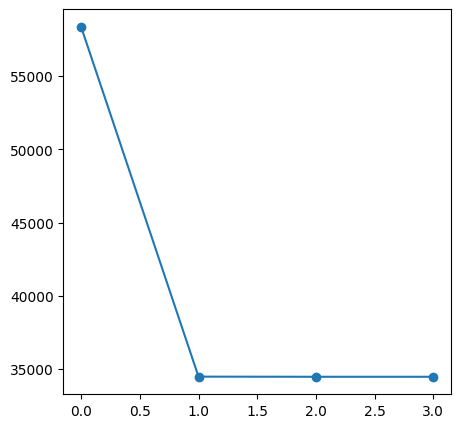

In [23]:
model = SGDMultipleLinearRegression()
model.fit_sgd(X_sc, y_train, tolerance=1e-02, batch_size=280, epochs=2000)

plt.figure(figsize=(5,5))
plt.plot(model.loss_history_, marker='o', linestyle="-")

In [88]:
model = MultipleLinearRegression()
model.fit(X_sc, y_train)

closed_form_loss = model.residual(X_sc, y_train)
cf_loss = np.mean((closed_form_loss)**2)
print(cf_loss)

20135.425315337798


In [46]:
model = SGDMultipleLinearRegression()
model.fit_sgd(X_sc, y_train, shuffle=True, seed=2)

model = SGDMultipleLinearRegression()
model.fit_sgd(X_sc, y_train)
print(model.loss_history_[:20])

Converged at:  16
Converged at:  16
[np.float64(58370.9353376969), np.float64(21953.526054082275), np.float64(20229.20552012403), np.float64(20140.848643195783), np.float64(20135.85950659699), np.float64(20135.482494148342), np.float64(20135.435869629782), np.float64(20135.42751214574), np.float64(20135.425787201177), np.float64(20135.425417454346), np.float64(20135.425337475597), np.float64(20135.425320138984), np.float64(20135.42531637917), np.float64(20135.425315563672), np.float64(20135.425315386794), np.float64(20135.425315348428), np.float64(20135.425315340104)]


`fit_gd` loss history:

[np.float64(58370.9353376969), np.float64(21953.526054082267), np.float64(20229.20552012403), np.float64(20140.848643195775), np.float64(20135.859506596993), np.float64(20135.482494148342), np.float64(20135.435869629782), np.float64(20135.42751214574), np.float64(20135.425787201177), np.float64(20135.425417454353)]

and 

`fit_sgd` loss history:

[np.float64(58370.9353376969), np.float64(21953.526054082275), np.float64(20229.20552012403), np.float64(20140.848643195783), np.float64(20135.85950659699), np.float64(20135.482494148342), np.float64(20135.435869629782), np.float64(20135.42751214574), np.float64(20135.425787201177), np.float64(20135.425417454346), np.float64(20135.425337475597), np.float64(20135.425320138984), np.float64(20135.42531637917), np.float64(20135.425315563672), np.float64(20135.425315386794), np.float64(20135.425315348428), np.float64(20135.425315340104)]

B = 32 and B = 1: band measured (last 10 losses minus closed-form loss).


Converged at:  252
4.406035216944097e-12
[3.82355100e+04 1.90780021e+11 7.48466476e+16 1.84781501e+09
 5.21649837e+04 2.34625300e+04 1.80358969e+04 1.51382043e+04
 1.28439041e+04 1.08711117e+04 9.20588233e+03 7.84963782e+03
 6.77764485e+03 5.94787321e+03 5.31393500e+03 4.83292112e+03
 4.46849168e+03 4.19110448e+03 3.97705366e+03 3.80736842e+03]


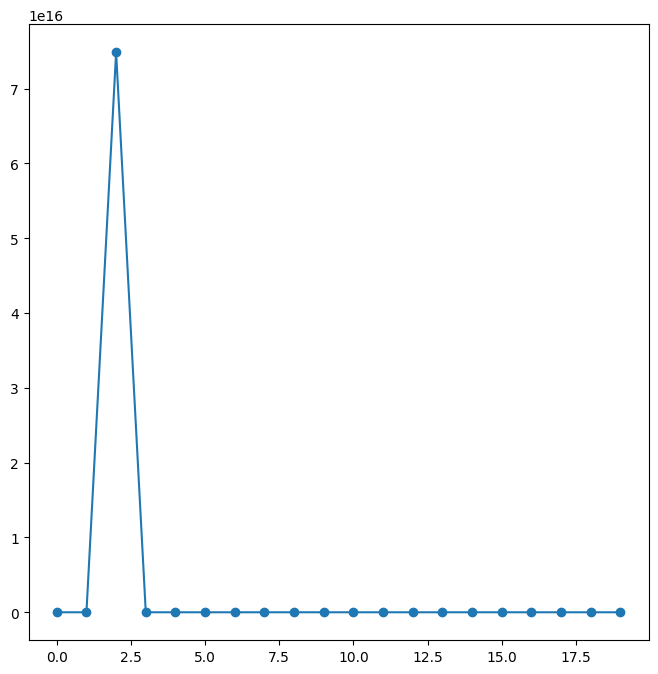

In [81]:
model = SGDMultipleLinearRegression()
model.fit_sgd(X_sc, y_train, batch_size=32, epochs=2000, decay_rate=0.1, decay_type='exponential')
print(model.lr_)
loss_history = model.loss_history_[:20]
band_measured = loss_history - cf_loss
print(band_measured)

plt.figure(figsize=(8, 8))
plt.plot(band_measured, marker='o')

Converged at:  261
1.7913602389580608e-12
[3.82355100e+004 6.98717671e+113 6.44993620e+223 5.23736751e+278
 5.20546976e+300 5.13970968e+295 1.92842869e+281 1.01672130e+260
 5.96421714e+233 5.89271008e+207 4.19773691e+183 7.67444416e+159
 5.59329361e+136 4.08761044e+115 6.21938474e+095 1.27475931e+077
 2.86393141e+059 6.23973380e+042 1.20591538e+027 1.91007273e+012]


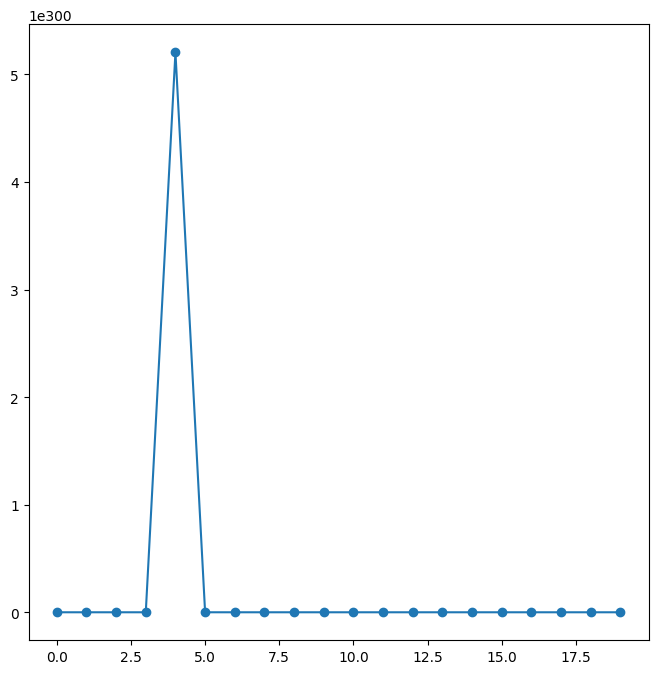

In [ ]:
model = SGDMultipleLinearRegression()
model.fit_sgd(X_sc, y_train, batch_size=13, epochs=2000, decay_rate=0.1, decay_type='exponential')
print(model.lr_)
loss_history = model.loss_history_[:20]
band_measured = loss_history - cf_loss
print(band_measured)

plt.figure(figsize=(8, 8))
plt.plot(band_measured, marker='o')

### Shuffle = true and Shuffle = False, on B = n, then use np.allclose against baseline to see if they match. then b=32 ran twice with same seed, plotted to see if both have same curves:

Converged at:  16
True
Converged at:  16
True


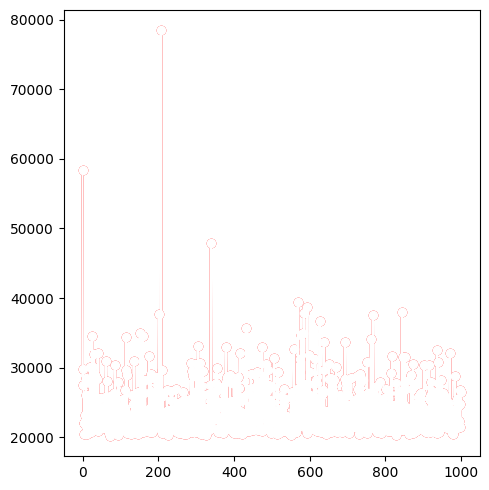

In [47]:
model = SGDMultipleLinearRegression()

model.fit_sgd(X_sc,y_train, shuffle=True)
print(np.allclose(model.loss_history_, baseline_losses, atol=1e-9))

model.fit_sgd(X_sc, y_train, shuffle=False)
print(np.allclose(model.loss_history_, baseline_losses, atol=1e-9))

## B = 32:
model.fit_sgd(X_sc, y_train, batch_size=32, shuffle=True, seed=46)
loss_plot1 = model.loss_history_.copy()

model.fit_sgd(X_sc, y_train, batch_size=32, shuffle=True, seed=46)
plt.figure(figsize=(5,5))
plt.plot(loss_plot1, marker='o', color='red')
plt.plot(model.loss_history_, marker='o', color='white')
plt.tight_layout()
plt.show()

### Testing code and fixing it !!

In [2]:
import numpy as np

In [73]:
class SGDLinearRegression():
    def __init__(self):
        self.beta_hat = None
        self.coef_ = None
        self.intercept_ = None
        self.lr_ = None
        self.lr_limit_ = None
        self.loss_history_ = None
        self.n_iter_ = None
        self.lr0_ = None
        self.lr_history_ = None
        self.stop_reason_ = 'max_epochs'
        self.final_loss_ = None

    def _add_intercept(self, X):
        X = np.asarray(X, float)

        return np.c_[np.ones(X.shape[0]), X]


    def _current_lr(self, epoch, lr0, decay_type=None, decay_rate=0.0):

        if decay_type is None:
            return lr0
        
        if decay_type == "time":
                return lr0 / (1 + decay_rate * epoch)

        elif decay_type == "exponential":
                return lr0 * np.exp(-decay_rate * epoch)

        else:
            raise ValueError(f"Decay type: {decay_type} not supported:\nSupported types : ['time', 'exponential']")
        




    def fit_sgd(self, X, y, batch_size=None,  epochs=1000, lr=None, tolerance=1e-08, decay_rate=0.0, decay_type=None, shuffle=True, seed=42):
        X = np.asarray(X, float)
        y = np.asarray(y, float).ravel()


        X = self._add_intercept(X)
        self.beta_hat = np.zeros(X.shape[1])

        XTX = X.T @ X
        n = X.shape[0]
        H = (2/n) * XTX

        eigen_values = np.linalg.eigvalsh(H)
        max_ev = np.max(eigen_values)

        self.lr_ = lr if lr is not None else 1/max_ev
        self.lr_limit_ = 2/max_ev
        self.lr0_ = self.lr_
        self.stop_reason_ = "max_epochs"

        if self.lr_ >= self.lr_limit_:
            print("Warning! lr_ is at or above the stability limit, expect divergence.")

        self.loss_history_ = []
        self.n_iter_ = epochs
        self.lr_history_ = []
        

        if batch_size is None: #if batch size isnot given, take the whole array of X
            batch_size = X.shape[0]
        else:
            batch_size = min(batch_size, n)
        rng = np.random.default_rng(seed) #seed to keep a fixed start okay !!

        for epoch in range(epochs):

            self.lr_ = self._current_lr(epoch, self.lr0_, decay_rate=decay_rate, decay_type=decay_type)
            
            indices = np.arange(len(X))
            if shuffle:
                rng.shuffle(indices)

            y_pred = X @ self.beta_hat #fit the whole complete X with the current beta get the loss and chec is loss is finite or not ! 
            loss = np.mean((y - y_pred)**2) #recording full dataset loss each epoch, before updates. 

            if not np.isfinite(loss):
                self.stop_reason_ = 'divergence'
                break

            self.loss_history_.append(loss)
            self.lr_history_.append(self.lr_)

            for start_index in range(0, len(X), batch_size): #make batches, find gradient, update 

                batch_indices = indices[start_index:start_index + batch_size]
        
                X_batch = X[batch_indices]
                y_batch = y[batch_indices]
                B = X_batch.shape[0]

                ## real cooking: 
                y_pred = X_batch @ self.beta_hat
                gradient = -(2/B) * X_batch.T @ (y_batch - y_pred) #the gradient points uphill to the highest slope, so we negate it t point to the smallest/lowest slope okay !!
                self.beta_hat = self.beta_hat - self.lr_ * gradient

            self.n_iter_ = epoch + 1

            if epoch > 0 and abs(self.loss_history_[-2] - self.loss_history_[-1]) < tolerance and batch_size >= n:
                self.stop_reason_ = 'tolerance'
                break

        y_pred = X @ self.beta_hat 
        self.final_loss_ = np.mean((y - y_pred)**2)
        if not np.isfinite(self.final_loss_):
            self.stop_reason_ = 'divergence'


        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def predict(self, X):
        if self.beta_hat is None:
            raise ValueError(".fit() not called yet, please fit the data")
        X = np.asarray(X, float)
        X = self._add_intercept(X)

        return X @  self.beta_hat

### Running tests with new class 

In [76]:
model = SGDLinearRegression()

model.fit_sgd(X_sc, y_train)

print(model.loss_history_)


print("\n", model.lr_history_)

print(model.stop_reason_)

[np.float64(58370.9353376969), np.float64(21953.526054082256), np.float64(20229.20552012403), np.float64(20140.848643195775), np.float64(20135.859506596993), np.float64(20135.482494148342), np.float64(20135.435869629782), np.float64(20135.42751214574), np.float64(20135.425787201177), np.float64(20135.425417454353), np.float64(20135.425337475594), np.float64(20135.425320138984), np.float64(20135.425316379173), np.float64(20135.425315563672), np.float64(20135.425315386794), np.float64(20135.425315348428), np.float64(20135.425315340104)]

 [np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748

In [ ]:
model = SGDLinearRegression()

model.fit_sgd(X_sc, y_train, decay_type='time', decay_rate=0.0)

print(model.loss_history_)
print("\n", model.lr_history_)

model = SGDLinearRegression()

model.fit_sgd(X_sc, y_train, decay_type='exponential', decay_rate=0.0)

print(model.loss_history_)
print("\n", model.lr_history_)

[np.float64(58370.9353376969), np.float64(21953.526054082256), np.float64(20229.20552012403), np.float64(20140.848643195775), np.float64(20135.859506596993), np.float64(20135.482494148342), np.float64(20135.435869629782), np.float64(20135.42751214574), np.float64(20135.425787201177), np.float64(20135.425417454353), np.float64(20135.425337475594), np.float64(20135.425320138984), np.float64(20135.425316379173), np.float64(20135.425315563672), np.float64(20135.425315386794), np.float64(20135.425315348428), np.float64(20135.425315340104)]

 [np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748835), np.float64(0.38749750278748

In [78]:
model = SGDLinearRegression()

model.fit_sgd(X_sc, y_train, batch_size=1, lr=0.39)

print(model.loss_history_)


print("\n", model.lr_history_)
print(model.stop_reason_)

[np.float64(58370.9353376969)]

 [0.39]
divergence


C:\Users\Sarthak\AppData\Local\Temp\ipykernel_10344\3698088044.py:101: RuntimeWarning: overflow encountered in matmul
  gradient = -(2/B) * X_batch.T @ (y_batch - y_pred) #the gradient points uphill to the highest slope, so we negate it t point to the smallest/lowest slope okay !!
C:\Users\Sarthak\AppData\Local\Temp\ipykernel_10344\3698088044.py:100: RuntimeWarning: invalid value encountered in matmul
  y_pred = X_batch @ self.beta_hat


In [81]:
model = SGDLinearRegression()

model.fit_sgd(X_sc, y_train, decay_type='time', decay_rate=0.1)

print(model.loss_history_)

print("\n", model.lr_history_)
print(model.stop_reason_)

[np.float64(58370.9353376969), np.float64(21953.526054082256), np.float64(20295.742937245326), np.float64(20156.357316045112), np.float64(20139.128556637963), np.float64(20136.267549083397), np.float64(20135.662087053126), np.float64(20135.50469267138), np.float64(20135.4559821784), np.float64(20135.43855949945), np.float64(20135.431552792063), np.float64(20135.428459001992), np.float64(20135.426987620533), np.float64(20135.426244889113), np.float64(20135.425851312943), np.float64(20135.42563416539), np.float64(20135.42551018965), np.float64(20135.425437288406), np.float64(20135.425393297493), np.float64(20135.425366135623), np.float64(20135.42534901568), np.float64(20135.425338021938), np.float64(20135.42533084105), np.float64(20135.425326076806), np.float64(20135.425322870025), np.float64(20135.425320682538), np.float64(20135.425319171685), np.float64(20135.425318116002), np.float64(20135.42531737029), np.float64(20135.425316838147), np.float64(20135.425316454737), np.float64(20135.4

band function: the mean of the last 10 losses minus the closed-form loss.

In [89]:
model = SGDLinearRegression()
model.fit_sgd(X_sc, y_train)

np.allclose(model.loss_history_, baseline_losses, atol=1e-9)

band_func = (np.mean(model.loss_history_[-10:])) - cf_loss

In [90]:
print(band_func)

0.00027990560556645505


loops over batch size, learning rate and decay rate: returns table of n_iter_ and stop_reason_

In [ ]:
lr = []
batch_size= []
decay_rate = []


AI Overview

        When training a linear regression model using Stochastic Gradient Descent (SGD), the optimal hyperparameters depend on your dataset's size and features. However, standard machine learning workflows rely on a common set of baseline values.
Here are 7 popular combinations of batch size, learning rate (α), and decay rate used in practice:

1. The Standard Baseline (No Decay)

• Batch Size: 32
• Learning Rate: 0.01
• Decay Rate: 0.0
• Best for: Small to medium datasets with normalized features. It is the most common starting point.

2. The Mini-Batch Default (Time-Based Decay)

• Batch Size: 64
• Learning Rate: 0.05
• Decay Rate: 1e-4 (0.0001)
• Best for: General use. The higher learning rate speeds up initial training, while the small decay stabilizes it later.

3. The Large-Batch Smooth Estimate

• Batch Size: 128
• Learning Rate: 0.1
• Decay Rate: 1e-3 (0.001)
• Best for: Larger, clean datasets. A larger batch size allows for a higher initial learning rate without causing divergence.

4. The Conservative Micro-Batch

• Batch Size: 16
• Learning Rate: 0.001
• Decay Rate: 0.0
• Best for: Noisy data or highly non-uniform features. The small learning rate prevents the model from jumping wildly between small batches.

5. The Aggressive Step-Down

• Batch Size: 32
• Learning Rate: 0.1
• Decay Rate: 1e-2 (0.01)
• Best for: Rapid early convergence. The high decay rate quickly shrinks the learning rate to avoid overshooting the minimum.

6. The Scaled Production Configuration

• Batch Size: 256
• Learning Rate: 0.05
• Decay Rate: 5e-4 (0.0005)
• Best for: Utilizing GPU acceleration on massive datasets where stability over millions of rows is required.

7. Pure Stochastic (Single-Sample) Tuning

• Batch Size: 1
• Learning Rate: 0.0001
• Decay Rate: 1e-5 (0.00001)
• Best for: Online learning (updating the model one data point at a time as new data arrives).
